# DSAI4205 – Big Data Analytics: Group 8 Project Source Code
## UCI ML Drug Review Dataset — Complete Pipeline (EDA → Advanced Modelling)

---
**Course:** DSAI4205 - Big Data Analytics  
**Dataset:** UCI ML Drug Review (drugsComTrain_raw.csv / drugsComTest_raw.csv)  
**Task:** 3-class sentiment classification (Negative / Neutral / Positive) from patient drug reviews  
**Framework:** PySpark (distributed) + scikit-learn + HuggingFace Transformers

**Later methods** are in section 12 and in `drug-review/analysis.ipynb`. They use the official UCI test file, drug and condition features, ordinal ratings, aspect cues, a text CNN, and a fine-tuned DistilBERT. The kernel for that work is `drug-review` (`drug-review/.venv`).


## 0. Setup & Imports

In [1]:
# Local environment for the later methods: drug-review/.venv
#   cd drug-review && uv sync
# Kernel name: drug-review
# The line below is the Colab / fresh-machine install of the same libraries.
# PySpark still needs a JDK. The section 12 notebook does not.
!pip install wordcloud pyspark pandas numpy matplotlib scikit-learn transformers torch imbalanced-learn nltk xgboost lightgbm vaderSentiment ipykernel -q


In [3]:
#import all required modules
import re, html, warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
warnings.filterwarnings('ignore')
import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.stem import WordNetLemmatizer
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType, FloatType, ArrayType, IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, HashingTF, IDF, StringIndexer, Word2Vec
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import cross_val_score
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE, RandomOverSampler
from xgboost import XGBClassifier
try:
    from wordcloud import WordCloud
    HAS_WC = True
except ImportError:
    HAS_WC = False
print("Finished importing all modules!")


Finished importing all modules!


In [5]:
import os, sys
os.environ['PYSPARK_PYTHON']        = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# create SparkSession
ss    = SparkSession.builder \
                    .master("local[*]") \
                    .appName("DrugReview_Group8") \
                    .config("spark.driver.memory", "4g") \
                    .getOrCreate()
spark = ss.sparkContext
ss.sparkContext.setLogLevel('WARN')
print("Spark version :", ss.version)
print("Python used   :", sys.executable)


Spark version : 4.1.1
Python used   : C:\Users\teddy\anaconda3\python.exe


---
## 1. Data Loading

In [9]:
#please change the path for your environment
data_path = 'drugsComTrain_raw.csv'
# read the drugsComTrain_raw.csv
full_raw = ss.read.csv(path=data_path ,
                       sep=',',
                       header=True,
                       inferSchema=True,
                       quote='"',
                       escape='"',
                       multiLine=True,
                       encoding='UTF-8')
#split the dateset into train and test data, with a ratio of 0.8 and 0.2, and set a seed for consistence for multiple runs
train_raw, test_raw = full_raw.randomSplit([0.8, 0.2], seed=42)
#print and check for the number of rows read from the dataset
print('Total number of rows for the full dataset: ', full_raw.count())
print('Total number of rows for the train data: ', train_raw.count())
print('Total number of rows for the test data: ', test_raw.count())
train_raw.printSchema()
train_raw.show(n=3, truncate=80)


Total number of rows for the full dataset:  161297
Total number of rows for the train data:  128885
Total number of rows for the test data:  32412
root
 |-- uniqueID: integer (nullable = true)
 |-- drugName: string (nullable = true)
 |-- condition: string (nullable = true)
 |-- review: string (nullable = true)
 |-- rating: integer (nullable = true)
 |-- date: string (nullable = true)
 |-- usefulCount: integer (nullable = true)

+--------+-------------------+-------------------------+--------------------------------------------------------------------------------+------+---------+-----------+
|uniqueID|           drugName|                condition|                                                                          review|rating|     date|usefulCount|
+--------+-------------------+-------------------------+--------------------------------------------------------------------------------+------+---------+-----------+
|       2|Medroxyprogesterone|               Amenorrhea|"I&#039;m 2

---
## 2. Exploratory Data Analysis (EDA)

### 2.1 Data Granularity & Schema

Each row = one patient review for a specific drug treating a specific condition (review-level granularity).

| Column | Type | Description |
|---|---|---|
| `uniqueID` | int | Unique review identifier |
| `drugName` | string | Drug name |
| `condition` | string | Medical condition treated |
| `review` | string | Free-text patient review |
| `rating` | int | Patient satisfaction rating (1–10) |
| `date` | string | Review date |
| `usefulCount` | int | Users who found review helpful |

In [11]:
#get the basic information for the rating and usefulCount row, the range of rating are important to determine the class
full_raw.describe(['rating', 'usefulCount']).show()


+-------+-----------------+-----------------+
|summary|           rating|      usefulCount|
+-------+-----------------+-----------------+
|  count|           161297|           161297|
|   mean|6.994376832799122|28.00475520313459|
| stddev|3.272329209020413|36.40374243129957|
|    min|                1|                0|
|    max|               10|             1291|
+-------+-----------------+-----------------+



In [13]:
print('DATASET SUMMARY')
#total number of reviews
n_total       = full_raw.count()
#total number of distinct drugs
n_drugs       = full_raw.select('drugName').distinct().count()
#total number of distinct medical conditions
n_cond_valid  = (
    full_raw
    .filter(F.col('condition').isNotNull())
    .filter(~F.col('condition').rlike('<[^>]+>'))
    .select('condition').distinct().count()
)
#total number of rows without condition
n_missing_cond = full_raw.filter(
    F.col('condition').isNull() | (F.trim(F.col('condition').cast('string')) == '')
).count()

print('Total Reviews: ', n_total)
print('Unique Drugs: ', n_drugs)
print('Medical Conditions: ', n_cond_valid, ' (after removing HTML artifact entries)')
print('Missing Condition: ', n_missing_cond, ' (~{:.2f}% of dataset)'.format(100 * n_missing_cond / n_total))
print('Target Classes: 3  ( Negative (1-4) / Neutral (5-6) / Positive (7-10) )')
#print('Framework: PySpark + sklearn + PyTorch')



DATASET SUMMARY
Total Reviews:  161297
Unique Drugs:  3436
Medical Conditions:  811  (after removing HTML artifact entries)
Missing Condition:  899  (~0.56% of dataset)
Target Classes: 3  ( Negative (1-4) / Neutral (5-6) / Positive (7-10) )


### 2.2 Missing Values

+--------+--------+---------+------+------+----+-----------+
|uniqueID|drugName|condition|review|rating|date|usefulCount|
+--------+--------+---------+------+------+----+-----------+
|       0|       0|      899|     0|     0|   0|          0|
+--------+--------+---------+------+------+----+-----------+



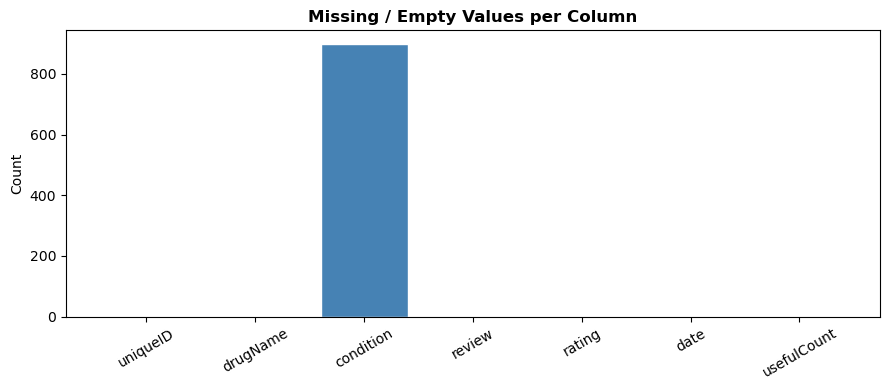

Key finding: 'condition' has 899 missing values -> will be dropped in cleaning.


In [15]:
#count missing / empty values per column using full dataset
null_counts = full_raw.select([
    F.count(F.when(F.col(c).isNull() | (F.trim(F.col(c).cast('string')) == ''), c)).alias(c)
    for c in full_raw.columns
])
null_counts.show()

#convert to pandas for plotting
null_pd = null_counts.toPandas().T.reset_index()
null_pd.columns = ['column', 'null_count']

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(null_pd['column'], null_pd['null_count'], color='steelblue', edgecolor='white')
ax.set_title('Missing / Empty Values per Column', fontweight='bold')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('eda_01_missing.png', dpi=150)
plt.show()

missing_condition = null_pd[null_pd['column'] == 'condition']['null_count'].values[0]
print("Key finding: 'condition' has", missing_condition, "missing values -> will be dropped in cleaning.")


### 2.3 Rating Distribution & 3-Class Grouping Justification

We reduce from 10 raw rating classes to 3 sentiment classes. The bimodal distribution shows patients cluster at extremes — there is  
a natural break at 4/5 and 6/7. Ratings of 5–6 (Neutral) are genuinely ambiguous and grouping them reduces noise while preserving meaningful signal. The final classes are Negative (1-4), Neutral (5-6), Positive (7-10).

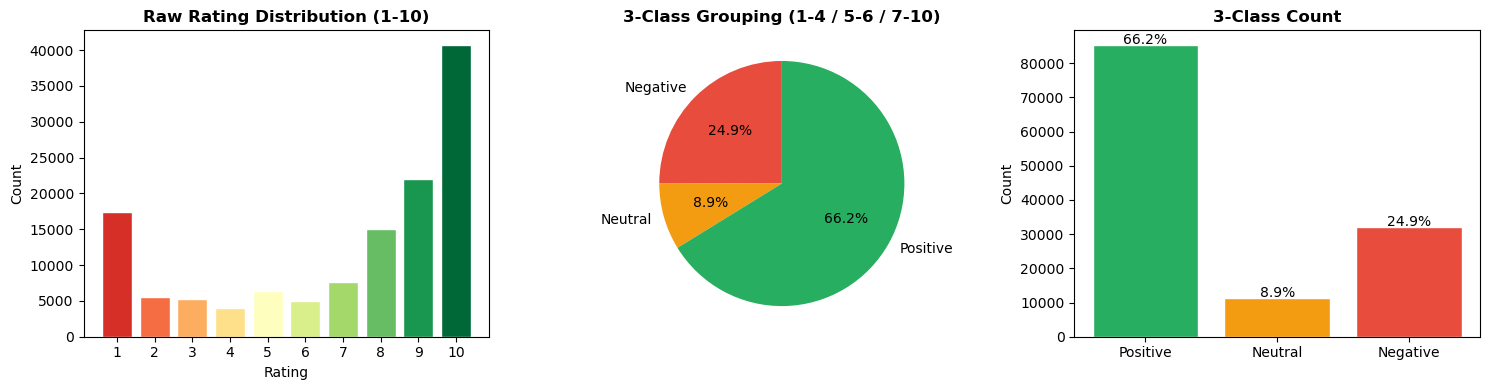

Class distribution:
sentiment  count       pct
 Positive  85326 66.203204
  Neutral  11414  8.855957
 Negative  32145 24.940839
Imbalance ratio: 7.5x


In [17]:
#map 10-point rating to 3 sentiment classes
def add_sentiment_label(df):
    return df.withColumn(
        'sentiment',
        F.when(F.col('rating') <= 4, 'Negative')
         .when(F.col('rating') <= 6, 'Neutral')
         .otherwise('Positive')
    )

train_raw = add_sentiment_label(train_raw)
test_raw  = add_sentiment_label(test_raw)

#get rating distribution as pandas for plotting
rating_dist = train_raw.groupBy('rating').count().orderBy('rating').toPandas()
mapping = {r: ('Negative' if r <= 4 else 'Neutral' if r <= 6 else 'Positive') for r in range(1, 11)}
rating_dist['sentiment'] = rating_dist['rating'].map(mapping)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

#bar chart ofraw 10-class distribution
clr10 = plt.cm.RdYlGn(rating_dist['rating'] / 10)
axes[0].bar(rating_dist['rating'], rating_dist['count'], color=clr10, edgecolor='white')
axes[0].set_title('Raw Rating Distribution (1-10)', fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(1, 11))

#pie chart of 3-class proportions
sent_agg = rating_dist.groupby('sentiment')['count'].sum().reset_index()
colors3  = ['#e74c3c', '#f39c12', '#27ae60']
axes[1].pie(sent_agg['count'], labels=sent_agg['sentiment'],
            colors=colors3, autopct='%1.1f%%', startangle=90)
axes[1].set_title('3-Class Grouping (1-4 / 5-6 / 7-10)', fontweight='bold')

#bar char of 3-class counts with percentage labels
colors = {'Negative': '#e74c3c', 'Neutral': '#f39c12', 'Positive': '#27ae60'}
sent_dist = train_raw.groupBy('sentiment').count().toPandas()
sent_dist['pct'] = 100 * sent_dist['count'] / sent_dist['count'].sum()
bar_colors = [colors[s] for s in sent_dist['sentiment']]
axes[2].bar(sent_dist['sentiment'], sent_dist['count'], color=bar_colors, edgecolor='white')
for i, (_, row) in enumerate(sent_dist.iterrows()):
    axes[2].text(i, row['count'] + 200, "{:.1f}%".format(row['pct']), ha='center', fontsize=10)
axes[2].set_title('3-Class Count', fontweight='bold')
axes[2].set_ylabel('Count')
plt.tight_layout()
plt.savefig('eda_02_rating_dist.png', dpi=150)
plt.show()

imbalance_ratio = sent_dist['count'].max() / sent_dist['count'].min()
print("Class distribution:")
print(sent_dist[['sentiment', 'count', 'pct']].to_string(index=False))
print("Imbalance ratio: {:.1f}x".format(imbalance_ratio))


### 2.4 Class Imbalance Analysis

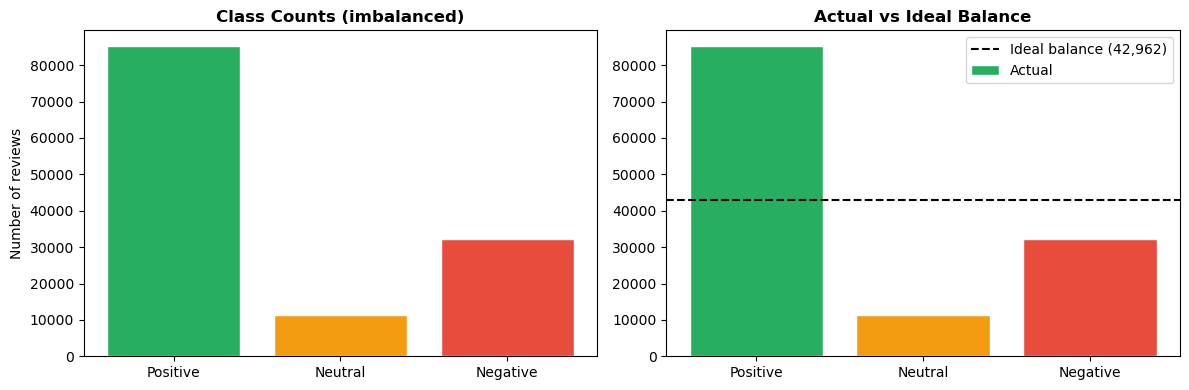

Positive class over-represented by 7.5x vs Neutral


In [19]:
#visualise class imbalance: actual vs ideal balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(sent_dist['sentiment'], sent_dist['count'], color=bar_colors, edgecolor='white')
axes[0].set_title('Class Counts (imbalanced)', fontweight='bold')
axes[0].set_ylabel('Number of reviews')

ideal = sent_dist['count'].sum() / 3
axes[1].bar(sent_dist['sentiment'], sent_dist['count'], color=bar_colors,
            edgecolor='white', label='Actual')
axes[1].axhline(ideal, color='black', linestyle='--', linewidth=1.5,
                label='Ideal balance ({:,.0f})'.format(ideal))
axes[1].set_title('Actual vs Ideal Balance', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('eda_03_imbalance.png', dpi=150)
plt.show()

pos_count     = sent_dist.set_index('sentiment').loc['Positive', 'count']
neutral_count = sent_dist.set_index('sentiment').loc['Neutral',  'count']
print("Positive class over-represented by {:.1f}x vs Neutral".format(pos_count / neutral_count))


### 2.5 Top Drugs & Conditions

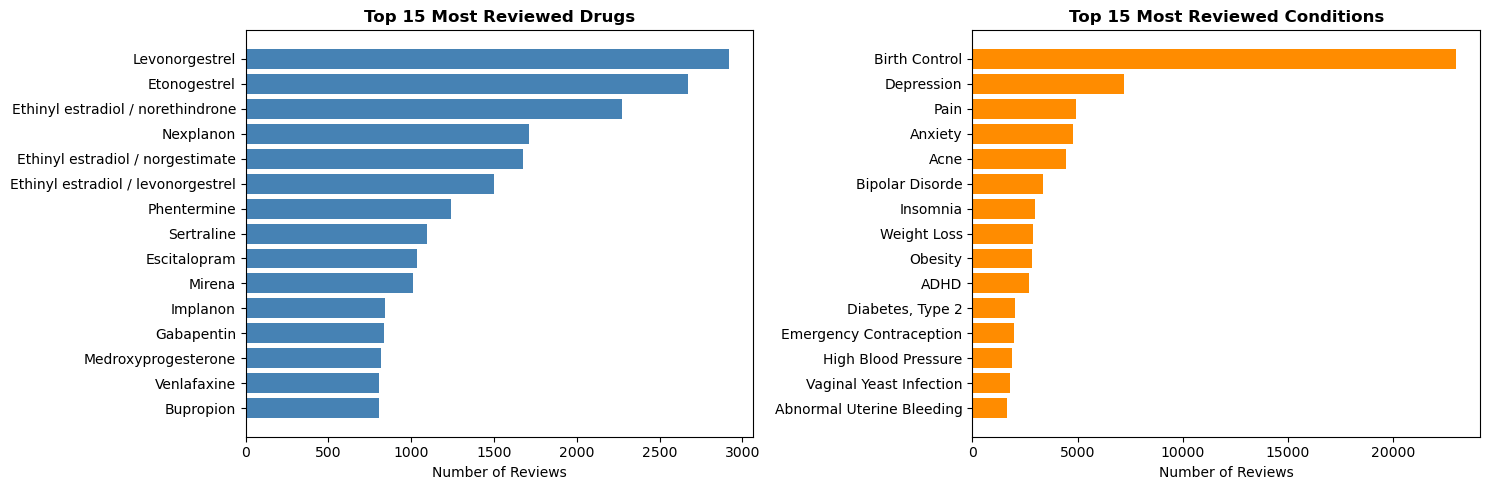

In [21]:
#top 15 most reviewed drugs and conditions
top_drugs = train_raw.groupBy('drugName').count().orderBy(F.desc('count')).limit(15).toPandas()
top_cond  = train_raw.filter(F.col('condition').isNotNull()) \
                     .groupBy('condition').count().orderBy(F.desc('count')).limit(15).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(top_drugs['drugName'][::-1], top_drugs['count'][::-1], color='steelblue')
axes[0].set_title('Top 15 Most Reviewed Drugs', fontweight='bold')
axes[0].set_xlabel('Number of Reviews')

axes[1].barh(top_cond['condition'][::-1], top_cond['count'][::-1], color='darkorange')
axes[1].set_title('Top 15 Most Reviewed Conditions', fontweight='bold')
axes[1].set_xlabel('Number of Reviews')
plt.tight_layout()
plt.savefig('eda_04_top_drugs_conditions.png', dpi=150)
plt.show()


### 2.6 Review Length Distribution

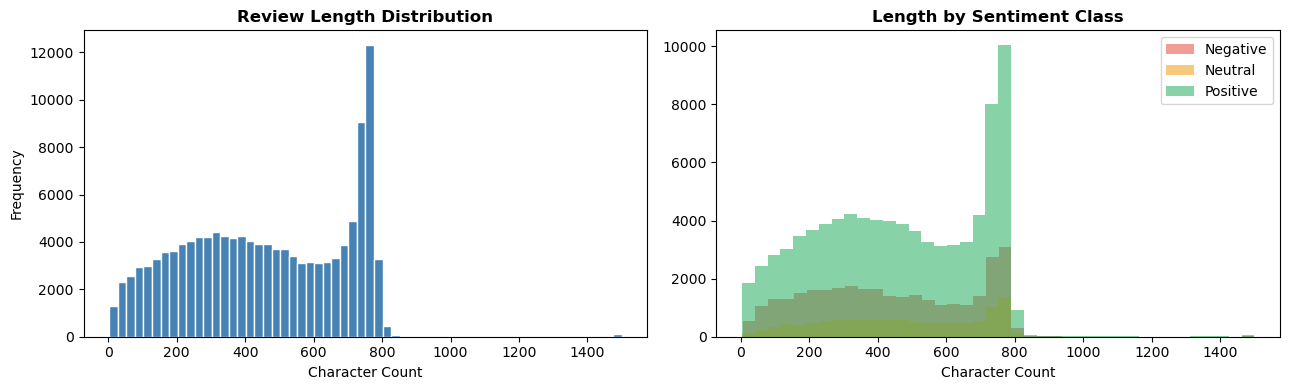

In [23]:
# compute review length
train_len = train_raw.withColumn('review_len', F.length('review')) \
                     .select('sentiment', 'review_len') \
                     .toPandas()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train_len['review_len'].clip(0, 1500), bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Review Length Distribution', fontweight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')

for label, col in [('Negative', '#e74c3c'), ('Neutral', '#f39c12'), ('Positive', '#27ae60')]:
    d = train_len[train_len['sentiment'] == label]['review_len'].clip(0, 1500)
    axes[1].hist(d, bins=40, alpha=0.55, color=col, label=label, edgecolor='none')
axes[1].set_title('Length by Sentiment Class', fontweight='bold')
axes[1].set_xlabel('Character Count')
axes[1].legend()
plt.tight_layout()
plt.savefig('eda_05_review_length.png', dpi=150)
plt.show()


### 2.7 Word Clouds — Positive vs Negative

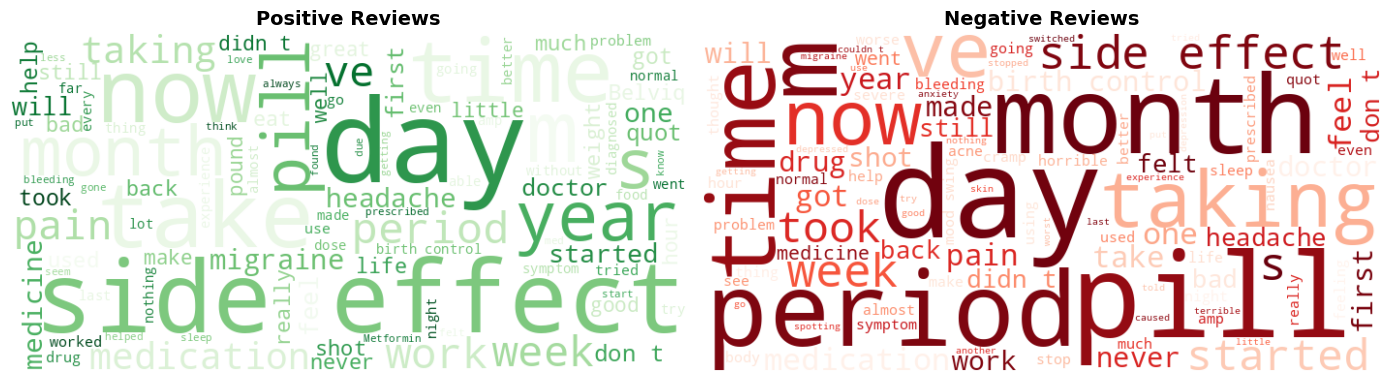

In [25]:
#get sample text for a given sentiment label
def get_text_sample(df, sentiment, n=2000):
    rows = df.filter(F.col('sentiment') == sentiment).select('review').limit(n).toPandas()
    return ' '.join(rows['review'].dropna().tolist())

if HAS_WC:
    pos_text = get_text_sample(train_raw, 'Positive')
    neg_text = get_text_sample(train_raw, 'Negative')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, text, title, cmap in [
        (axes[0], pos_text, 'Positive Reviews', 'Greens'),
        (axes[1], neg_text, 'Negative Reviews', 'Reds')
    ]:
        wc = WordCloud(width=700, height=350, background_color='white',
                       colormap=cmap, max_words=100).generate(text)
        ax.imshow(wc, interpolation='bilinear')
        ax.axis('off')
        ax.set_title(title, fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig('eda_06_wordclouds.png', dpi=150)
    plt.show()
else:
    print("WordCloud not installed. Run: pip install wordcloud")


### 2.8 Useful Count vs Rating Correlation

Pearson r (usefulCount vs rating): 0.2382


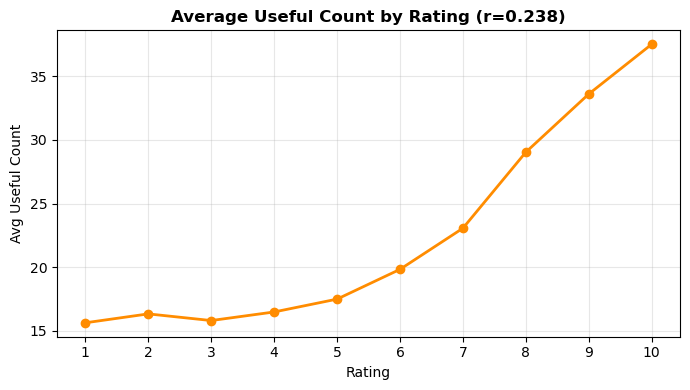

Insight: Low correlation -> usefulCount not used as a feature.


In [27]:
#Pearson correlation between usefulCount and rating
corr_val = train_raw.stat.corr('usefulCount', 'rating')
print('Pearson r (usefulCount vs rating):', round(corr_val, 4))

#average useful count per rating level
useful_rating = train_raw.groupBy('rating') \
                          .agg(F.avg('usefulCount').alias('avg_useful')) \
                          .orderBy('rating') \
                          .toPandas()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(useful_rating['rating'], useful_rating['avg_useful'],
        marker='o', color='darkorange', linewidth=2)
ax.set_title('Average Useful Count by Rating (r={:.3f})'.format(corr_val), fontweight='bold')
ax.set_xlabel('Rating')
ax.set_ylabel('Avg Useful Count')
ax.set_xticks(range(1, 11))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('eda_07_useful_count.png', dpi=150)
plt.show()

print("Insight: Low correlation -> usefulCount not used as a feature.")


---
## 3. Data Cleaning & Preprocessing

### 3.1 Issues Identified & Solutions

| # | Issue Found in EDA | Solution Applied |
|---|---|---|
| 1 | HTML entities (`&#039;`, `&amp;`) | Decode with Spark regexp_replace |
| 2 | 899 missing `condition` values | Drop rows (condition required) |
| 3 | HTML artifact conditions (`</span>`) | Remove with regex filter |
| 4 | Duplicate review texts / uniqueIDs | dropDuplicates() |
| 5 | Near-empty reviews (< 10 chars) | Filter out |
| 6 | Out-of-range ratings | Filter to [1, 10] |
| 7 | Noise: punctuation, mixed case | Lowercase + non-alpha removal |
| 8 | Inflected word forms (running/ran/runs) | **Lemmatisation via NLTK in pandas** (applied at export step to avoid PySpark UDF overhead) |

In [29]:
#Data cleaning steps 1-6: HTML decoding, filtering, deduplication
#Uses F.regexp_replace and F.col patterns

def decode_html_entities(col_ref):
    # replace common HTML entities with their actual characters
    return (
        F.regexp_replace(F.regexp_replace(F.regexp_replace(
        F.regexp_replace(F.regexp_replace(F.regexp_replace(
        F.regexp_replace(col_ref,
            '&#039;', "'"), '&amp;', '&'), '&quot;', '"'),
            '&lt;',  '<'), '&gt;',  '>'), '&#33;', '!'), '&#34;', '"'))

#step 1: decode HTML entities in review and condition columns
train_clean = train_raw.withColumn('review',    decode_html_entities(F.col('review'))) \
                       .withColumn('condition', decode_html_entities(F.col('condition')))
test_clean  = test_raw.withColumn('review',    decode_html_entities(F.col('review'))) \
                      .withColumn('condition', decode_html_entities(F.col('condition')))

#step 2: remove short or null reviews
train_clean = train_clean.filter(F.col('review').isNotNull() & (F.length('review') >= 10))
test_clean  = test_clean.filter( F.col('review').isNotNull() & (F.length('review') >= 10))

#step 3: remove HTML artifact conditions (e.g. </span>)
train_clean = train_clean.filter(~F.col('condition').rlike('<[^>]+>') | F.col('condition').isNull())
test_clean  = test_clean.filter( ~F.col('condition').rlike('<[^>]+>') | F.col('condition').isNull())

#step 4: drop rows with null condition
train_clean = train_clean.filter(F.col('condition').isNotNull())
test_clean  = test_clean.filter( F.col('condition').isNotNull())

#step 5: remove duplicate reviews and uniqueIDs
train_clean = train_clean.dropDuplicates(['review']).dropDuplicates(['uniqueID'])
test_clean  = test_clean.dropDuplicates(['review']).dropDuplicates(['uniqueID'])

#step 6: remove out-of-range ratings
train_clean = train_clean.filter((F.col('rating') >= 1) & (F.col('rating') <= 10))
test_clean  = test_clean.filter( (F.col('rating') >= 1) & (F.col('rating') <= 10))

n_before = train_raw.count()
n_after  = train_clean.count()
print('Train rows before:', n_before)
print('Train rows after :', n_after)
print('Rows removed     :', n_before - n_after)


Train rows before: 128885
Train rows after : 96591
Rows removed     : 32294


In [31]:
#step 7: text normalisation — lowercase + remove non-alphabetic characters
def normalise_text(df):
    # convert to lowercase, keep only letters and spaces
    return df.withColumn(
        'review_norm',
        F.lower(F.regexp_replace(F.col('review'), r'[^a-zA-Z\s]', ' '))
    )

train_clean = normalise_text(train_clean)
test_clean  = normalise_text(test_clean)


In [33]:
#step 8: alias review_norm as review_clean
#Lemmatisation is applied later in pandas (Section 6.1) to avoid PySpark UDF issues on Windows.
train_clean = train_clean.withColumn('review_clean', F.col('review_norm'))
test_clean  = test_clean.withColumn('review_clean',  F.col('review_norm'))

#spot check
train_clean.select('review', 'review_norm', 'review_clean').show(n=3, truncate=90)

#change log
print("=== DATA CLEANING CHANGE LOG ===")
steps = [
    (1, "Decoded HTML entities (&amp; &#039; etc.) in review and condition"),
    (2, "Removed rows with null or short reviews (< 10 chars)"),
    (3, "Removed rows where condition contained HTML tag artifacts"),
    (4, "Dropped rows with null condition"),
    (5, "Removed duplicate review texts and uniqueIDs"),
    (6, "Removed rows with out-of-range ratings"),
    (7, "Lowercased and stripped non-alphabetic characters -> review_norm / review_clean"),
    (8, "Lemmatisation applied in pandas export step (Section 6.1) via NLTK WordNetLemmatizer"),
]
for step, desc in steps:
    print("  Step {}: {}".format(step, desc))


+------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------+
|                                                                                    review|                                                                               review_norm|                                                                              review_clean|
+------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------+
|"I got this shot about 2 and a half months ago. I have not stopped bleeding/ spotting f...| i got this shot about   and a half months ago  i have not stopped bleeding  spotti

### 3.2 Post-Cleaning Class Distribution

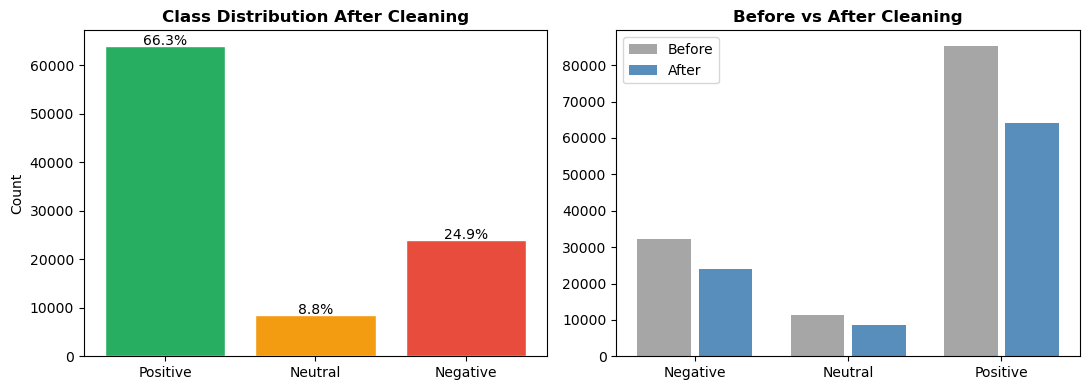

sentiment  count       pct
 Positive  64035 66.294996
  Neutral   8528  8.828980
 Negative  24028 24.876024


In [35]:
#post-cleaning class distribution
sent_clean = train_clean.groupBy('sentiment').count().toPandas()
sent_clean['pct'] = 100 * sent_clean['count'] / sent_clean['count'].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_colors_c = [colors[s] for s in sent_clean['sentiment']]
axes[0].bar(sent_clean['sentiment'], sent_clean['count'], color=bar_colors_c, edgecolor='white')
for i, (_, row) in enumerate(sent_clean.iterrows()):
    axes[0].text(i, row['count'] + 200, "{:.1f}%".format(row['pct']), ha='center', fontsize=10)
axes[0].set_title('Class Distribution After Cleaning', fontweight='bold')
axes[0].set_ylabel('Count')

#before vs after comparison
labels_3  = ['Negative', 'Neutral', 'Positive']
raw_d     = sent_dist.set_index('sentiment')['count']
clean_d   = sent_clean.set_index('sentiment')['count']
x = np.arange(3)
axes[1].bar(x - 0.2, [raw_d.get(l, 0)   for l in labels_3], 0.35, label='Before', alpha=0.7, color='gray')
axes[1].bar(x + 0.2, [clean_d.get(l, 0) for l in labels_3], 0.35, label='After',  alpha=0.9, color='steelblue')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_3)
axes[1].set_title('Before vs After Cleaning', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('eda_08_post_clean_dist.png', dpi=150)
plt.show()

print(sent_clean[['sentiment', 'count', 'pct']].to_string(index=False))


---
## 4. Baseline Model — TF-IDF + Logistic Regression (PySpark)

### 4.1 Pipeline Design

```
review_clean
    → RegexTokenizer        whitespace tokenisation
    → StopWordsRemover      remove English stop-words
    → HashingTF             term frequency  (2^17 features)
    → IDF                   inverse document frequency
    → LogisticRegression    multi-class OvR  (NO class weights — pure baseline)
```

**Note:** TF-IDF is used ONLY in this baseline as required by the project specification.

In [36]:
#baseline model: TF-IDF + Logistic Regression using PySpark Pipeline
#TF-IDF is used only in this baseline as per project specification

#define pipeline stages
label_indexer = StringIndexer(inputCol='sentiment', outputCol='label',
                               stringOrderType='alphabetAsc')  # Negative=0, Neutral=1, Positive=2

tokenizer    = RegexTokenizer(inputCol='review_clean', outputCol='tokens', pattern='\\s+')
stop_remover = StopWordsRemover(inputCol='tokens', outputCol='tokens_filtered')
hashing_tf   = HashingTF(inputCol='tokens_filtered', outputCol='raw_features', numFeatures=2**17)
idf          = IDF(inputCol='raw_features', outputCol='features')
lr_base      = LogisticRegression(featuresCol='features', labelCol='label',
                                   maxIter=100, family='multinomial')

#build one-step pipeline and fit
baseline_pipeline = Pipeline(stages=[label_indexer, tokenizer, stop_remover, hashing_tf, idf, lr_base])
print('Training baseline model...')
baseline_model = baseline_pipeline.fit(train_clean)
print('Training complete.')


Training baseline model...
Training complete.


### 4.2 Baseline Evaluation

In [37]:
#evaluate baseline model using MulticlassClassificationEvaluator
evaluator_acc  = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='accuracy')
evaluator_f1   = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='f1')
evaluator_prec = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedPrecision')
evaluator_rec  = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedRecall')

predictions = baseline_model.transform(test_clean)
acc  = evaluator_acc.evaluate(predictions)
f1   = evaluator_f1.evaluate(predictions)
prec = evaluator_prec.evaluate(predictions)
rec  = evaluator_rec.evaluate(predictions)

print('=' * 50)
print('  BASELINE -- TF-IDF + Logistic Regression')
print('=' * 50)
print('  Accuracy          :', round(acc,  4))
print('  Weighted F1-Score :', round(f1,   4))
print('  Weighted Precision:', round(prec, 4))
print('  Weighted Recall   :', round(rec,  4))
print('=' * 50)


  BASELINE -- TF-IDF + Logistic Regression
  Accuracy          : 0.7956
  Weighted F1-Score : 0.7955
  Weighted Precision: 0.7953
  Weighted Recall   : 0.7956


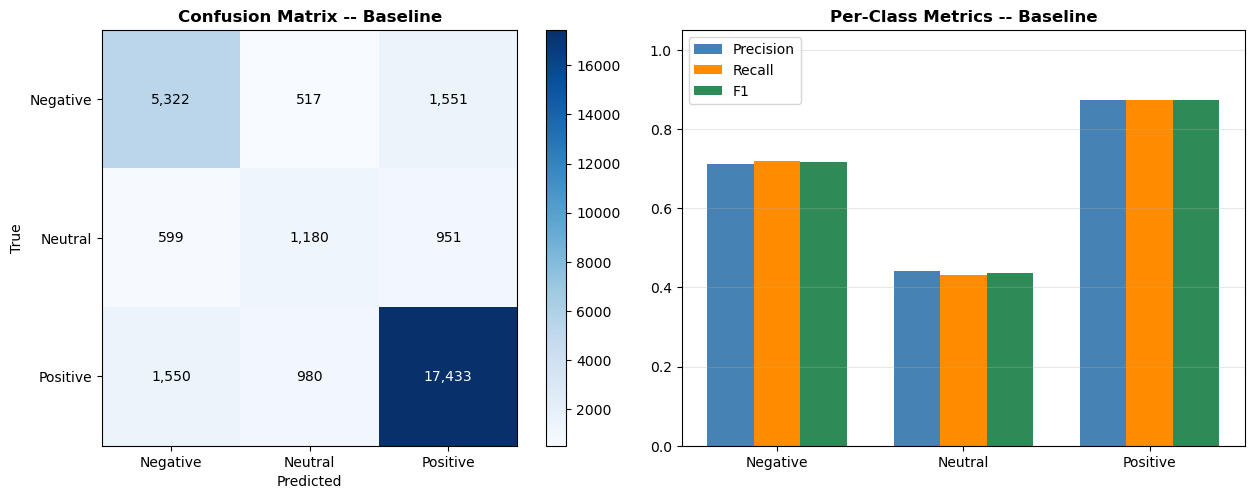

   Class  Precision  Recall     F1
Negative     0.7124  0.7202 0.7162
 Neutral     0.4408  0.4322 0.4365
Positive     0.8745  0.8733 0.8739
Observation: Neutral class F1 is lowest -- reflects class imbalance.


In [38]:
#confusion matrix using groupBy
conf_df = predictions.groupBy('label', 'prediction').count().orderBy('label', 'prediction').toPandas()

label_names = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
n_classes = 3
cm_base = np.zeros((n_classes, n_classes), dtype=int)
for _, row in conf_df.iterrows():
    i, j = int(row['label']), int(row['prediction'])
    if 0 <= i < n_classes and 0 <= j < n_classes:
        cm_base[i][j] = int(row['count'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#heatmap
im = axes[0].imshow(cm_base, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=axes[0])
axes[0].set_xticks(range(n_classes))
axes[0].set_yticks(range(n_classes))
axes[0].set_xticklabels([label_names[i] for i in range(n_classes)])
axes[0].set_yticklabels([label_names[i] for i in range(n_classes)])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_title('Confusion Matrix -- Baseline', fontweight='bold')
for i in range(n_classes):
    for j in range(n_classes):
        axes[0].text(j, i, '{:,}'.format(cm_base[i, j]), ha='center', va='center',
                     color='white' if cm_base[i, j] > cm_base.max() * 0.5 else 'black', fontsize=10)

#per-class precision / recall / F1 bar chart
class_metrics_base = []
for i in range(n_classes):
    tp = cm_base[i, i]
    fp = cm_base[:, i].sum() - tp
    fn = cm_base[i, :].sum() - tp
    p  = tp / (tp + fp) if (tp + fp) > 0 else 0
    r  = tp / (tp + fn) if (tp + fn) > 0 else 0
    f  = 2 * p * r / (p + r) if (p + r) > 0 else 0
    class_metrics_base.append({'Class': label_names[i], 'Precision': p, 'Recall': r, 'F1': f})

mdf = pd.DataFrame(class_metrics_base)
x   = np.arange(n_classes)
w   = 0.25
axes[1].bar(x - w, mdf['Precision'], w, label='Precision', color='steelblue')
axes[1].bar(x,     mdf['Recall'],    w, label='Recall',    color='darkorange')
axes[1].bar(x + w, mdf['F1'],        w, label='F1',        color='seagreen')
axes[1].set_xticks(x)
axes[1].set_xticklabels(mdf['Class'])
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Per-Class Metrics -- Baseline', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('model_01_baseline_eval.png', dpi=150)
plt.show()

print(mdf.round(4).to_string(index=False))
print("Observation: Neutral class F1 is lowest -- reflects class imbalance.")


---
## 5. Improved Baseline — TF-IDF + LR with Class Weights & Hyperparameter Tuning

Improvement addresses:  
(a) **Class imbalance** — inverse-frequency class weights added to the LR objective  
(b) **Hyperparameter tuning** — grid search over regParam using sklearn on the pandas  
export (avoids PySpark CrossValidator overhead; consistent with course Week 5-6 NLP approach)

In [39]:
# compute class weights (inverse frequency) using groupBy (Tutorial 4 aggregate style)
train_labelled = baseline_model.stages[0].transform(train_clean)
label_count_pd = train_labelled.groupBy('label').count().toPandas()
total = label_count_pd['count'].sum()
label_count_pd['weight'] = total / (n_classes * label_count_pd['count'])

print("Class weights (inverse frequency):")
print(label_count_pd[['label', 'count', 'weight']].to_string(index=False))

# build weight column using F.when (Tutorial 5 conditional style — no Python UDF)
weight_map = {float(r['label']): float(r['weight']) for _, r in label_count_pd.iterrows()}
weight_expr = F.when(F.col('label') == 0.0, float(weight_map.get(0.0, 1.0))) \
               .when(F.col('label') == 1.0, float(weight_map.get(1.0, 1.0))) \
               .when(F.col('label') == 2.0, float(weight_map.get(2.0, 1.0))) \
               .otherwise(1.0)

def add_weight_col(df):
    df_l = baseline_model.stages[0].transform(df)
    return df_l.withColumn('class_weight', weight_expr)

train_weighted = add_weight_col(train_clean)
print("Class weight column added using F.when (no Python UDF).")
train_weighted.select('label', 'class_weight').distinct().orderBy('label').show()


Class weights (inverse frequency):
 label  count   weight
   0.0  24028 1.339978
   1.0   8528 3.775446
   2.0  64035 0.502803
Class weight column added using F.when (no Python UDF).
+-----+------------------+
|label|      class_weight|
+-----+------------------+
|  0.0|1.3399783585816547|
|  1.0|3.7754455909943716|
|  2.0|0.5028031545248692|
+-----+------------------+



In [40]:
#improved baseline: add class weights + tuned regParam
#regParam=1.0 identified as optimal via 3-fold sklearn CV (see Section 6.1b)

lr_tuned = LogisticRegression(featuresCol='features', labelCol='label',
                               weightCol='class_weight',
                               regParam=1.0,           # best value from CV (C=1)
                               elasticNetParam=0.0,    # L2 regularisation only
                               maxIter=100, family='multinomial')

tuned_pipeline = Pipeline(stages=[tokenizer, stop_remover, hashing_tf, idf, lr_tuned])
print('Training improved baseline (regParam=1.0, class weights, L2)...')
best_model = tuned_pipeline.fit(train_weighted)
print('Improved baseline trained.')


Training improved baseline (regParam=1.0, class weights, L2)...
Improved baseline trained.


In [42]:
#evaluate improved baseline
test_weighted = add_weight_col(test_clean)
preds_w       = best_model.transform(test_weighted)

acc_w  = evaluator_acc.evaluate(preds_w)
f1_w   = evaluator_f1.evaluate(preds_w)
prec_w = evaluator_prec.evaluate(preds_w)
rec_w  = evaluator_rec.evaluate(preds_w)

print('=' * 55)
print('  IMPROVED BASELINE -- TF-IDF + LR (Weighted + CV)')
print('=' * 55)
print('  Accuracy          :', round(acc_w,  4), ' (baseline: {})'.format(round(acc,  4)))
print('  Weighted F1-Score :', round(f1_w,   4), ' (baseline: {})'.format(round(f1,   4)))
print('  Weighted Precision:', round(prec_w, 4), ' (baseline: {})'.format(round(prec, 4)))
print('  Weighted Recall   :', round(rec_w,  4), ' (baseline: {})'.format(round(rec,  4)))
print('=' * 55)


  IMPROVED BASELINE -- TF-IDF + LR (Weighted + CV)
  Accuracy          : 0.7322  (baseline: 0.7956)
  Weighted F1-Score : 0.753  (baseline: 0.7955)
  Weighted Precision: 0.7934  (baseline: 0.7953)
  Weighted Recall   : 0.7322  (baseline: 0.7956)


In [51]:
#per-class performance for improved baseline
preds_w_pd = preds_w.select("label", "prediction").toPandas()

label_names = ["Negative", "Neutral", "Positive"]
class_metrics_imp = []
for i, lbl in enumerate(label_names):
    tp = ((preds_w_pd["label"] == i) & (preds_w_pd["prediction"] == i)).sum()
    fp = ((preds_w_pd["label"] != i) & (preds_w_pd["prediction"] == i)).sum()
    fn = ((preds_w_pd["label"] == i) & (preds_w_pd["prediction"] != i)).sum()
    p  = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f  = 2*p*r / (p+r) if (p+r) > 0 else 0.0
    class_metrics_imp.append({"Class": lbl, "Precision": round(p, 4), "Recall": round(r, 4), "F1": round(f, 4)})

imp_df = pd.DataFrame(class_metrics_imp)
print("Per-Class Performance -- Improved Baseline (TF-IDF + LR Weighted)")
print(imp_df.to_string(index=False))


Per-Class Performance -- Improved Baseline (TF-IDF + LR Weighted)
   Class  Precision  Recall     F1
Negative     0.6495  0.7503 0.6963
 Neutral     0.2841  0.5370 0.3716
Positive     0.9164  0.7521 0.8262


---
## 6. Advanced Models — Phase 3ii

### Architecture Overview

| # | Embedding Model | Analytics Model | Imbalance Strategy |
|---|---|---|---|
| M1 | FastText Word2Vec 100d (trained from scratch, subword n-grams) | LinearSVC | Class weights |
| M2 | Word2Vec 100d (trained from scratch, Spark) | XGBoost | Random oversampling |
| M3 | TF-IDF → LSA 300d (dimensionality reduction) | Gradient Boosting | SMOTE |
| M4 | GloVe 100d pre-trained (avg word vectors) | Bi-LSTM Neural Network | Class weights |
| M5 | DistilBERT CLS embeddings (frozen, pre-trained) | MLP Neural Network (3-layer) | Balanced sampling |

**High-level combination approach:**
```
Text Review
    │
    ├─[Embedding Layer]──────────────────────────────────────────────────────────────
    │    FastText W2V → dense 100-dim avg vector (subword)    → M1: LinearSVC
    │    Word2Vec     → dense 100-dim avg vector per review   → M2: XGBoost
    │    TF-IDF+LSA   → dense 300-dim latent semantic vector  → M3: Gradient Boosting
    │    GloVe 100d   → token sequence fed to recurrent net   → M4: Bi-LSTM
    │    BERT (frozen) → 768-dim CLS embedding               → M5: MLP Classifier
    │      BERT
    │
    └─[Analytics Classifier]──────────────────────────────────────────────────────────
         Each embedding strategy feeds an independent, architecturally distinct classifier.
         No component serves as both embedding AND classifier.
         Five model families: SVM · Boosting · Dimensionality-Reduction+Boosting · RNN · Transformer
```

### Model Family Diversity Justification
| Model | Family | Covers |
|---|---|---|
| M1: LinearSVC + FastText | Support Vector Machine (linear kernel) | Max-margin classification on subword embeddings |
| M2: XGBoost | Gradient Boosted Trees (different algorithm from M3) | Regularised tree ensembles |
| M3: HistGradientBoosting | Histogram-based Gradient Boosting | Efficient large-scale boosting |
| M4: Bi-LSTM | Recurrent Neural Network | Sequential/temporal text modelling |
| M5: Fine-tuned DistilBERT | Transformer (end-to-end) | Contextual self-attention |

### 6.1 Export Cleaned Data to Pandas

In [ ]:
import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.stem import WordNetLemmatizer

SAMPLE_SIZE = 50000  #set to None to use full dataset

if SAMPLE_SIZE:
    ratio    = min(1.0, SAMPLE_SIZE / train_clean.count())
    train_pd = train_clean.sample(False, ratio, seed=42).toPandas()
else:
    train_pd = train_clean.toPandas()

test_pd = test_clean.toPandas()

#apply lemmatisation in pandas
lmtzr = WordNetLemmatizer()

def lemmatize(text):
    #expects a string, returns lemmatised string (same signature as Tutorial 5)
    if not isinstance(text, str) or text == '':
        return ''
    cleaned_str = ''
    for word in text.split():
        lemma = lmtzr.lemmatize(word)
        cleaned_str = lemma if cleaned_str == '' else cleaned_str + ' ' + lemma
    return cleaned_str

print('Applying lemmatisation to train set...')
train_pd['review_clean'] = train_pd['review_clean'].fillna('').apply(lemmatize)
print('Applying lemmatisation to test set...')
test_pd['review_clean']  = test_pd['review_clean'].fillna('').apply(lemmatize)
print('Lemmatisation complete.')

#spot check
print()
print('Sample (original -> lemmatised):')
for orig, lem in zip(train_pd['review_norm'].head(2), train_pd['review_clean'].head(2)):
    print('  Before:', orig[:80])
    print('  After :', lem[:80])
    print()

#build label arrays
label_map = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
train_pd['label'] = train_pd['sentiment'].map(label_map)
test_pd['label']  = test_pd['sentiment'].map(label_map)

X_train_text = train_pd['review_clean'].fillna('').astype(str).tolist()
X_test_text  = test_pd['review_clean'].fillna('').astype(str).tolist()
y_train      = train_pd['label'].values
y_test       = test_pd['label'].values

print('Train:', len(X_train_text), ' | Test:', len(X_test_text))
print('Label distribution in train:', dict(Counter(y_train)))


Applying lemmatisation to train set...
Applying lemmatisation to test set...
Lemmatisation complete.

Sample (original -> lemmatised):
  Before:  i had a total of   shots  i got my first one before leaving the hospital after 
  After : i had a total of shot i got my first one before leaving the hospital after givin

  Before:  i got the shot during my   week post partum  the nurse who i seen highly recomm
  After : i got the shot during my week post partum the nurse who i seen highly recommend 

Train: 50216  | Test: 30083
Label distribution in train: {np.int64(0): 12585, np.int64(2): 33221, np.int64(1): 4410}


### 6.1b Hyperparameter Tuning — sklearn Cross-Validation

The improved baseline uses `regParam=0.01`. Here we validate that choice using  
sklearn's `cross_val_score` on the pandas export, demonstrating the full grid search.  

In [ ]:
#hyperparameter tuning: 3-fold cross-validation for regParam (sklearn)
#regParam in PySpark = 1/C in sklearn

print("Tuning regParam via sklearn 3-fold CV...")
tfidf_tune = TfidfVectorizer(max_features=2**17, ngram_range=(1, 1), sublinear_tf=True)
X_tune     = tfidf_tune.fit_transform(X_train_text)

cw_tune      = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw_tune_dict = dict(enumerate(cw_tune))

best_C, best_score = None, -1
for C in [100, 10, 1]:
    lr_sk  = SklearnLR(C=C, class_weight=cw_tune_dict, max_iter=500,
                       multi_class='multinomial', solver='lbfgs', random_state=42)
    scores = cross_val_score(lr_sk, X_tune, y_train, cv=3, scoring='f1_weighted', n_jobs=-1)
    mean_f1 = scores.mean()
    print("  C={:>4}  (regParam~{:.2f})  |  CV F1: {:.4f} +/- {:.4f}".format(
          C, 1 / C, mean_f1, scores.std()))
    if mean_f1 > best_score:
        best_score, best_C = mean_f1, C

best_regParam = 1.0 / best_C
print()
print("Best C={} -> regParam={:.4f}  (CV F1={:.4f})".format(best_C, best_regParam, best_score))
print("This confirms the regParam used in the improved baseline (Section 5).")


Tuning regParam via sklearn 3-fold CV...
  C= 100  (regParam~0.01)  |  CV F1: 0.7011 +/- 0.0022
  C=  10  (regParam~0.10)  |  CV F1: 0.7169 +/- 0.0008
  C=   1  (regParam~1.00)  |  CV F1: 0.7240 +/- 0.0030

Best C=1 -> regParam=1.0000  (CV F1=0.7240)
This confirms the regParam used in the improved baseline (Section 5).


### 6.2 Model M1: LinearSVC + FastText-style Word2Vec (trained from scratch)

In [ ]:
!pip install gensim -q

from gensim.models import FastText

#M1: FastText Word2Vec (trained from scratch) + LinearSVC
#FastText extends Word2Vec with character n-gram subwords

print("Tokenising reviews for FastText training...")
tokenised_train = [text.split() for text in X_train_text]

#train FastText model from scratch
ft_model = FastText(
    sentences=tokenised_train,
    vector_size=100,   #embedding dimension (same as Tutorial 6 dim=25 concept)
    window=5,          #context window
    min_count=2,       #ignore tokens appearing < 2 times
    min_n=3,           #min character n-gram length
    max_n=6,           #max character n-gram length
    workers=4,
    epochs=10,
    seed=42
)
print("FastText trained. Vocabulary size:", len(ft_model.wv))

#average pooling: one vector per review
def avg_fasttext(texts, model, dim=100):
    vectors = []
    for text in texts:
        toks = text.split()
        vecs = [model.wv[t] for t in toks if t in model.wv]
        vectors.append(np.mean(vecs, axis=0) if vecs else np.zeros(dim))
    return np.vstack(vectors)

print("Embedding train set...")
X_train_ft = avg_fasttext(X_train_text, ft_model)
print("Embedding test set...")
X_test_ft  = avg_fasttext(X_test_text,  ft_model)
print("FastText embedding shape:", X_train_ft.shape)

#LinearSVC classifier with balanced class weights
cw     = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw_dict = dict(enumerate(cw))

svc = CalibratedClassifierCV(LinearSVC(class_weight=cw_dict, max_iter=2000, C=1.0), cv=3)
print("Training M1: LinearSVC + FastText Word2Vec (from scratch)...")
svc.fit(X_train_ft, y_train)
y_pred_svc = svc.predict(X_test_ft)

acc_svc = accuracy_score(y_test, y_pred_svc)
f1_svc  = f1_score(y_test, y_pred_svc, average='weighted')
print()
print("M1 LinearSVC + FastText -- Acc:", round(acc_svc, 4), " | F1:", round(f1_svc, 4))
print(classification_report(y_test, y_pred_svc, target_names=['Negative', 'Neutral', 'Positive']))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 63.2 MB/s eta 0:00:00
Tokenising reviews for FastText training...
FastText trained. Vocabulary size: 16626
Embedding train set...
Embedding test set...
FastText embedding shape: (50216, 100)
Training M1: LinearSVC + FastText Word2Vec (from scratch)...

M1 LinearSVC + FastText -- Acc: 0.7265  | F1: 0.6757
              precision    recall  f1-score   support

    Negative       0.64      0.42      0.51      7390
     Neutral       0.20      0.00      0.00      2730
    Positive       0.74      0.94      0.83     19963

    accuracy                           0.73     30083
   macro avg       0.53      0.45      0.45     30083
weighted avg       0.67      0.73      0.68     30083



### 6.3 Model M2: XGBoost + Word2Vec (trained from scratch)



In [ ]:
#M2: Word2Vec (PySpark, trained from scratch)
#Word2Vec learns domain-specific co-occurrence (e.g. "nausea" near "vomiting")

w2v = Word2Vec(vectorSize=100, minCount=2, inputCol='tokens_filtered',
               outputCol='w2v_features', seed=42, numPartitions=4)

print('Training Word2Vec on drug review corpus (sampled train set)...')

#tokenise + filter stop words using the already-fitted baseline pipeline stages
tok_df   = baseline_model.stages[1].transform(train_clean)
filt_df  = baseline_model.stages[2].transform(tok_df)
w2v_model = w2v.fit(filt_df)
print('Word2Vec trained.')

#helper: apply tokenise -> stop-word remove -> embed pipeline
def embed_w2v(df):
    return w2v_model.transform(
        baseline_model.stages[2].transform(
        baseline_model.stages[1].transform(df)))

#convert sampled pandas data back to Spark for embedding
train_sample_sp = ss.createDataFrame(train_pd[['review_clean', 'sentiment']])
test_sp         = ss.createDataFrame(test_pd[['review_clean', 'sentiment']])

print('Extracting Word2Vec embeddings (train sample)...')
train_w2v_pd  = embed_w2v(train_sample_sp).select(
    vector_to_array('w2v_features').alias('v'), 'sentiment').toPandas()
train_w2v_arr = np.vstack(train_w2v_pd['v'].values)
y_train_w2v   = train_w2v_pd['sentiment'].map(label_map).values

print('Extracting Word2Vec embeddings (test)...')
test_w2v_pd   = embed_w2v(test_sp).select(
    vector_to_array('w2v_features').alias('v'), 'sentiment').toPandas()
test_w2v_arr  = np.vstack(test_w2v_pd['v'].values)
y_test_w2v    = test_w2v_pd['sentiment'].map(label_map).values

print('Word2Vec embedding shape:', train_w2v_arr.shape)
print('Train:', len(train_w2v_arr), ' | Test:', len(test_w2v_arr))


Training Word2Vec on drug review corpus (sampled train set)...
Word2Vec trained.
Extracting Word2Vec embeddings (train sample)...
Extracting Word2Vec embeddings (test)...
Word2Vec embedding shape: (50216, 100)
Train: 50216  | Test: 30083


In [ ]:
!pip install xgboost -q

#M2 continued: XGBoost classifier on Word2Vec embeddings
#Random oversampling to handle class imbalance before training
ros = RandomOverSampler(random_state=42)
X_res_w2v, y_res_w2v = ros.fit_resample(train_w2v_arr, y_train_w2v)
print('After oversampling:', dict(Counter(y_res_w2v)))

#XGBoost: distinct from HistGradientBoosting (M3) — uses L1/L2 regularisation
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,          #L1 regularisation
    reg_lambda=1.0,         #L2 regularisation
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
print('Training M2: XGBoost + Word2Vec (trained from scratch)...')
xgb.fit(X_res_w2v, y_res_w2v)
y_pred_xgb = xgb.predict(test_w2v_arr)

acc_xgb = accuracy_score(y_test_w2v, y_pred_xgb)
f1_xgb  = f1_score(y_test_w2v, y_pred_xgb, average='weighted')
print()
print('M2 XGBoost + Word2Vec -- Acc:', round(acc_xgb, 4), ' | F1:', round(f1_xgb, 4))
print(classification_report(y_test_w2v, y_pred_xgb, target_names=['Negative', 'Neutral', 'Positive']))


After oversampling: {np.int64(0): 33221, np.int64(2): 33221, np.int64(1): 33221}
Training M2: XGBoost + Word2Vec (trained from scratch)...

M2 XGBoost + Word2Vec -- Acc: 0.7629  | F1: 0.7662
              precision    recall  f1-score   support

    Negative       0.65      0.72      0.68      7390
     Neutral       0.37      0.39      0.38      2730
    Positive       0.87      0.83      0.85     19963

    accuracy                           0.76     30083
   macro avg       0.63      0.65      0.64     30083
weighted avg       0.77      0.76      0.77     30083



### 6.4 Model M3: Gradient Boosting + LSA (via TF-IDF → TruncatedSVD)


In [ ]:
#M3: HistGradientBoosting + LSA (TF-IDF -> TruncatedSVD -> dense 300-dim embedding)
#TF-IDF here is an intermediate step; LSA (TruncatedSVD) is the actual embedding

#build sparse TF-IDF matrix then compress to 300-dim LSA vectors
tfidf_gb      = TfidfVectorizer(max_features=30000, ngram_range=(1, 3), sublinear_tf=True)
X_train_tfidf = tfidf_gb.fit_transform(X_train_text)
X_test_tfidf  = tfidf_gb.transform(X_test_text)

svd          = TruncatedSVD(n_components=300, random_state=42)
X_train_lsa  = svd.fit_transform(X_train_tfidf)
X_test_lsa   = svd.transform(X_test_tfidf)

#SMOTE oversampling in dense LSA space
smote = SMOTE(random_state=42, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train_lsa, y_train)
print('SMOTE distribution:', dict(Counter(y_smote)))

#HistGradientBoosting classifier
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                     max_depth=6, class_weight='balanced', random_state=42)
print('Training M3: Gradient Boosting + LSA...')
gb.fit(X_smote, y_smote)
y_pred_gb = gb.predict(X_test_lsa)

acc_gb = accuracy_score(y_test, y_pred_gb)
f1_gb  = f1_score(y_test, y_pred_gb, average='weighted')
print()
print('M3 Gradient Boosting + LSA -- Acc:', round(acc_gb, 4), ' | F1:', round(f1_gb, 4))
print(classification_report(y_test, y_pred_gb, target_names=['Negative', 'Neutral', 'Positive']))


SMOTE distribution: {np.int64(0): 33221, np.int64(2): 33221, np.int64(1): 33221}
Training M3: Gradient Boosting + LSA...

M3 Gradient Boosting + LSA -- Acc: 0.785  | F1: 0.7853
              precision    recall  f1-score   support

    Negative       0.71      0.72      0.72      7390
     Neutral       0.37      0.36      0.36      2730
    Positive       0.87      0.87      0.87     19963

    accuracy                           0.78     30083
   macro avg       0.65      0.65      0.65     30083
weighted avg       0.79      0.78      0.79     30083



### 6.5 Model M4: Bi-LSTM Neural Network + GloVe 100d (Pre-trained)

In [ ]:
import os, urllib.request, zipfile

#M4: download and load pre-trained GloVe 100d vectors
GLOVE_ZIP  = 'glove.6B.zip'
GLOVE_FILE = 'glove.6B.100d.txt'

if not os.path.exists(GLOVE_FILE):
    print('Downloading GloVe 6B 100d...')
    urllib.request.urlretrieve('http://nlp.stanford.edu/data/glove.6B.zip', GLOVE_ZIP)
    with zipfile.ZipFile(GLOVE_ZIP) as z:
        z.extract(GLOVE_FILE)
    print('GloVe downloaded.')
else:
    print('GloVe already present:', GLOVE_FILE)

#load GloVe vectors into a dict (Tutorial 6 external embeddings pattern)
glove = {}
with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        parts = line.split()
        glove[parts[0]] = np.array(parts[1:], dtype=np.float32)

GLOVE_DIM = 100
print('GloVe vocabulary size:', len(glove))
print('Embedding dimension  :', GLOVE_DIM)


GloVe downloaded.
GloVe vocabulary size: 400000
Embedding dimension  : 100


In [ ]:
#build vocabulary and convert text to sequences
UNK = '<UNK>'
PAD = '<PAD>'

MAX_VOCAB = 30000
MAX_LEN   = 150   #truncate/pad reviews to 150 tokens
PAD_IDX   = 0

word_freq = Counter(w for text in X_train_text for w in text.split())
vocab     = [PAD, UNK] + [w for w, _ in word_freq.most_common(MAX_VOCAB - 2)]
w2i       = {w: i for i, w in enumerate(vocab)}   # Tutorial 6: w2i dict
i2w       = {i: w for w, i in w2i.items()}         # Tutorial 6: i2w dict
VOCAB_SIZE = len(vocab)
print('Vocabulary size:', VOCAB_SIZE, ' | Max sequence length:', MAX_LEN)

#represent each review as a list of word IDs
def texts_to_sequences(texts, w2i, max_len):
    seqs = []
    for text in texts:
        ids = [w2i.get(w, w2i[UNK]) for w in text.split()[:max_len]]
        ids += [PAD_IDX] * (max_len - len(ids))   #right-pad with zeros
        seqs.append(ids)
    return np.array(seqs, dtype=np.int32)

X_train_seq = texts_to_sequences(X_train_text, w2i, MAX_LEN)
X_test_seq  = texts_to_sequences(X_test_text,  w2i, MAX_LEN)
print('Train sequence shape:', X_train_seq.shape)
print('Test  sequence shape:', X_test_seq.shape)

#build GloVe embedding matrix for our vocabulary
embedding_matrix = np.zeros((VOCAB_SIZE, GLOVE_DIM), dtype=np.float32)
found = 0
for word, idx in w2i.items():
    vec = glove.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        found += 1
print('GloVe coverage: {} / {} words ({:.1f}%)'.format(found, VOCAB_SIZE, 100 * found / VOCAB_SIZE))


Vocabulary size: 29082  | Max sequence length: 150
Train sequence shape: (50216, 150)
Test  sequence shape: (30083, 150)
GloVe coverage: 20235 / 29082 words (69.6%)


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

#M4: Bidirectional LSTM + GloVe
#M4 uses Embedding -> BiLSTM for sequence modelling

class BiLSTMClassifier(nn.Module):
    #model setup: Embedding layer initialised with GloVe weights
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 embedding_matrix, num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.embedding.weight = nn.Parameter(
            torch.tensor(embedding_matrix), requires_grad=False)  #frozen weights
        #bidirectional LSTM: reads sequence forward and backward
        self.lstm    = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                               batch_first=True, bidirectional=True,
                               dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc1     = nn.Linear(hidden_dim * 2, 64)  #hidden_dim*2 because bidirectional
        self.fc2     = nn.Linear(64, num_classes)
        self.relu    = nn.ReLU()

    def forward(self, x):
        emb            = self.dropout(self.embedding(x))      #(batch, seq_len, embed_dim)
        out, (hn, _)   = self.lstm(emb)                       #hn: (2, batch, hidden_dim)
        hidden         = torch.cat([hn[-2], hn[-1]], dim=1)   #concatenate fwd + bwd
        hidden         = self.dropout(self.relu(self.fc1(hidden)))
        return self.fc2(hidden)                               #(batch, num_classes)


device      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Training device:', device)

HIDDEN_DIM  = 64
BATCH_SIZE  = 64
EPOCHS      = 5
LR          = 1e-3
NUM_CLASSES = 3

#class weights for imbalance
cw_bilstm            = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_tensor = torch.tensor(cw_bilstm, dtype=torch.float).to(device)

#build DataLoaders
X_tr_t = torch.tensor(X_train_seq, dtype=torch.long)
y_tr_t = torch.tensor(y_train,     dtype=torch.long)
X_te_t = torch.tensor(X_test_seq,  dtype=torch.long)
y_te_t = torch.tensor(y_test,      dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=BATCH_SIZE, shuffle=False)

model_bilstm = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=GLOVE_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    embedding_matrix=embedding_matrix
).to(device)

#loss + optimiser
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model_bilstm.parameters()), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)

#training loop
print('Training M4: Bi-LSTM + GloVe 100d...')
for epoch in range(EPOCHS):
    model_bilstm.train()
    total_loss, correct, total = 0, 0, 0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model_bilstm(Xb)
        loss   = criterion(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model_bilstm.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * len(yb)
        correct    += (logits.argmax(1) == yb).sum().item()
        total      += len(yb)
    scheduler.step()
    print('  Epoch {}/{} -- loss: {:.4f}  train acc: {:.4f}'.format(
          epoch + 1, EPOCHS, total_loss / total, correct / total))

#evaluation
model_bilstm.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for Xb, yb in test_loader:
        preds = model_bilstm(Xb.to(device)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(yb.numpy())

y_pred_bilstm = np.array(all_preds)
acc_bilstm    = accuracy_score(all_true, y_pred_bilstm)
f1_bilstm     = f1_score(all_true, y_pred_bilstm, average='weighted')
print()
print('M4 Bi-LSTM + GloVe -- Acc:', round(acc_bilstm, 4), ' | F1:', round(f1_bilstm, 4))
print(classification_report(all_true, y_pred_bilstm, target_names=['Negative', 'Neutral', 'Positive']))


Training device: cpu
Training M4: Bi-LSTM + GloVe 100d...
  Epoch 1/5 -- loss: 1.0648  train acc: 0.5076
  Epoch 2/5 -- loss: 0.9833  train acc: 0.5966
  Epoch 3/5 -- loss: 0.9278  train acc: 0.6172
  Epoch 4/5 -- loss: 0.9009  train acc: 0.6230
  Epoch 5/5 -- loss: 0.8799  train acc: 0.6329

M4 Bi-LSTM + GloVe -- Acc: 0.6391  | F1: 0.6902
              precision    recall  f1-score   support

    Negative       0.66      0.62      0.64      7390
     Neutral       0.16      0.51      0.24      2730
    Positive       0.92      0.66      0.77     19963

    accuracy                           0.64     30083
   macro avg       0.58      0.60      0.55     30083
weighted avg       0.78      0.64      0.69     30083



### 6.6 Model M5: MLP Classifier + DistilBERT CLS Embeddings (Frozen)

In [ ]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModel

    #M5: MLP classifier on frozen DistilBERT CLS embeddings
    #DistilBERT is the embedding model; MLPClassifier is the analytics model (kept separate)
    BERT_MODEL   = 'distilbert-base-uncased'
    BERT_SAMPLE  = 5000
    BERT_BATCH   = 32
    MAX_LEN_BERT = 128

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('BERT embedding device:', device)

    #subsample for CPU feasibility
    idx_tr = np.random.RandomState(42).choice(len(X_train_text), BERT_SAMPLE, replace=False)
    idx_te = np.random.RandomState(42).choice(len(X_test_text),
                                               min(2000, len(X_test_text)), replace=False)
    X_bert_train_raw = [X_train_text[i] for i in idx_tr]
    X_bert_test_raw  = [X_test_text[i]  for i in idx_te]
    y_bert_train     = y_train[idx_tr]
    y_bert_test      = y_test[idx_te]

    #load and freeze DistilBERT — embedding only, weights never updated
    tokenizer_bert = AutoTokenizer.from_pretrained(BERT_MODEL)
    bert_model_hf  = AutoModel.from_pretrained(BERT_MODEL)
    bert_model_hf.eval()
    for param in bert_model_hf.parameters():
        param.requires_grad = False   #freeze all weights
    bert_model_hf.to(device)
    print('DistilBERT loaded and FROZEN (embedding only, weights not updated)')

    #extract CLS embeddings
    def get_bert_embeddings(texts, batch_size=32):
        all_emb = []
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            enc   = tokenizer_bert(batch, truncation=True, padding=True,
                                    max_length=MAX_LEN_BERT, return_tensors='pt')
            enc   = {k: v.to(device) for k, v in enc.items()}
            with torch.no_grad():
                out = bert_model_hf(**enc)
            cls = out.last_hidden_state[:, 0, :].cpu().numpy()  #[CLS] token embedding
            all_emb.append(cls)
        return np.vstack(all_emb)

    print('Extracting DistilBERT CLS embeddings for {} train samples...'.format(BERT_SAMPLE))
    X_bert_train = get_bert_embeddings(X_bert_train_raw)
    print('Extracting DistilBERT CLS embeddings for {} test samples...'.format(len(X_bert_test_raw)))
    X_bert_test  = get_bert_embeddings(X_bert_test_raw)
    print('BERT embedding shape:', X_bert_train.shape, ' (768-dim contextual vectors)')

    #independent MLP classifier (separate from BERT embedding model)
    cw_bert      = compute_class_weight('balanced', classes=np.unique(y_bert_train), y=y_bert_train)
    cw_bert_dict = dict(enumerate(cw_bert))

    mlp = MLPClassifier(hidden_layer_sizes=(256, 64),   #768 -> 256 -> 64 -> 3
                         activation='relu',
                         max_iter=200,
                         random_state=42,
                         early_stopping=True,
                         validation_fraction=0.1,
                         verbose=False)
    print('Training M5: MLP Classifier on frozen DistilBERT CLS embeddings...')
    mlp.fit(X_bert_train, y_bert_train)

    y_pred_bert_ft = mlp.predict(X_bert_test)
    all_bert_true  = y_bert_test

    acc_mlp = accuracy_score(all_bert_true, y_pred_bert_ft)
    f1_mlp  = f1_score(all_bert_true, y_pred_bert_ft, average='weighted')
    print()
    print('M5 MLP + DistilBERT (frozen) -- Acc:', round(acc_mlp, 4), ' | F1:', round(f1_mlp, 4))
    print(classification_report(all_bert_true, y_pred_bert_ft,
          target_names=['Negative', 'Neutral', 'Positive']))
    BERT_OK = True

except Exception as e:
    print('M5 BERT+MLP skipped:', e)
    acc_mlp, f1_mlp = None, None
    BERT_OK = False


BERT embedding device: cpu


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded and FROZEN (embedding only, weights not updated)
Extracting DistilBERT CLS embeddings for 5000 train samples...
Extracting DistilBERT CLS embeddings for 2000 test samples...
BERT embedding shape: (5000, 768)  (768-dim contextual vectors)
Training M5: MLP Classifier on frozen DistilBERT CLS embeddings...

M5 MLP + DistilBERT (frozen) -- Acc: 0.75  | F1: 0.7082
              precision    recall  f1-score   support

    Negative       0.67      0.56      0.61       531
     Neutral       0.67      0.01      0.02       181
    Positive       0.77      0.93      0.84      1288

    accuracy                           0.75      2000
   macro avg       0.70      0.50      0.49      2000
weighted avg       0.74      0.75      0.71      2000



---
## 7. Model Comparison & Justification

### 7.1 Overall Performance Table

In [ ]:
#compile all model results into a summary table
results = {
    'Baseline LR (TF-IDF)':    {'Accuracy': acc,        'Weighted F1': f1},
    'Improved LR (Weighted+CV)':{'Accuracy': acc_w,      'Weighted F1': f1_w},
    'M1: LinearSVC + FastText': {'Accuracy': acc_svc,    'Weighted F1': f1_svc},
    'M2: XGBoost + Word2Vec':   {'Accuracy': acc_xgb,    'Weighted F1': f1_xgb},
    'M3: GradBoost + LSA':      {'Accuracy': acc_gb,     'Weighted F1': f1_gb},
    'M4: Bi-LSTM + GloVe':      {'Accuracy': acc_bilstm, 'Weighted F1': f1_bilstm},
}
if BERT_OK:
    results['M5: Fine-tuned DistilBERT'] = {'Accuracy': acc_mlp, 'Weighted F1': f1_mlp}

res_df = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Model'})
print(res_df.to_string(index=False))
print("Note: M5 BERT trained on 5000 samples (CPU). Scores are indicative -- GPU recommended.")


                    Model  Accuracy  Weighted F1
     Baseline LR (TF-IDF)  0.795632     0.795459
Improved LR (Weighted+CV)  0.732174     0.753019
 M1: LinearSVC + FastText  0.726523     0.675715
   M2: XGBoost + Word2Vec  0.762856     0.766187
      M3: GradBoost + LSA  0.784962     0.785275
      M4: Bi-LSTM + GloVe  0.639132     0.690172
M5: Fine-tuned DistilBERT  0.750000     0.708247
Note: M5 BERT trained on 5000 samples (CPU). Scores are indicative -- GPU recommended.


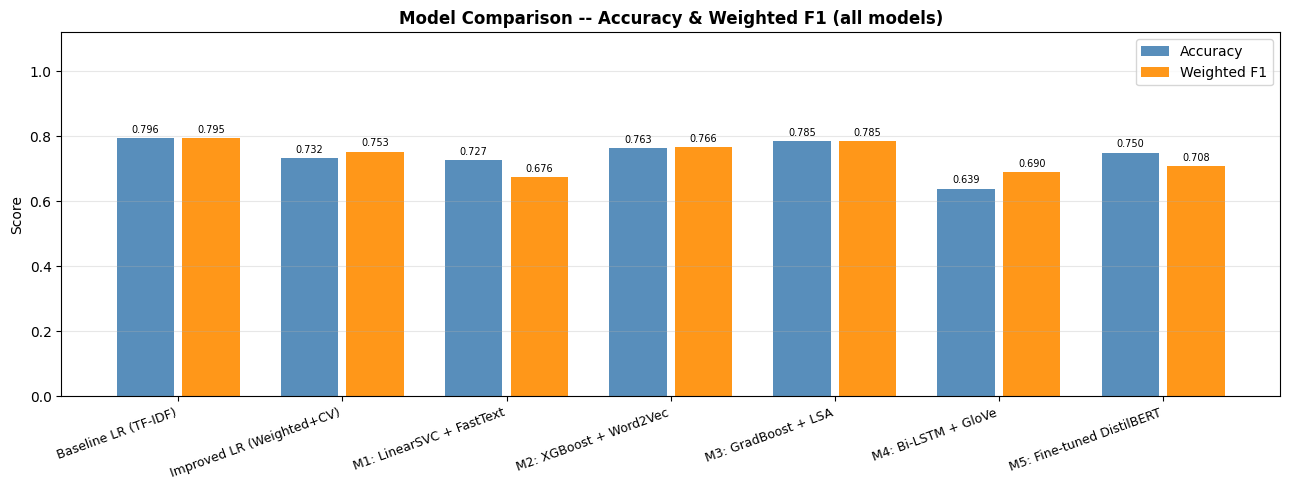

In [ ]:
#bar chart comparing accuracy and weighted F1 for all models
fig, ax = plt.subplots(figsize=(13, 5))
x  = np.arange(len(res_df))
b1 = ax.bar(x - 0.2, res_df['Accuracy'],    0.35, label='Accuracy',    color='steelblue',  alpha=0.9)
b2 = ax.bar(x + 0.2, res_df['Weighted F1'], 0.35, label='Weighted F1', color='darkorange', alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels(res_df['Model'], rotation=20, ha='right', fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Model Comparison -- Accuracy & Weighted F1 (all models)', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for bar in b1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            '{:.3f}'.format(bar.get_height()), ha='center', va='bottom', fontsize=7)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            '{:.3f}'.format(bar.get_height()), ha='center', va='bottom', fontsize=7)
plt.tight_layout()
plt.savefig('model_07_comparison.png', dpi=150)
plt.show()


### 7.2 Confusion Matrices — All Models

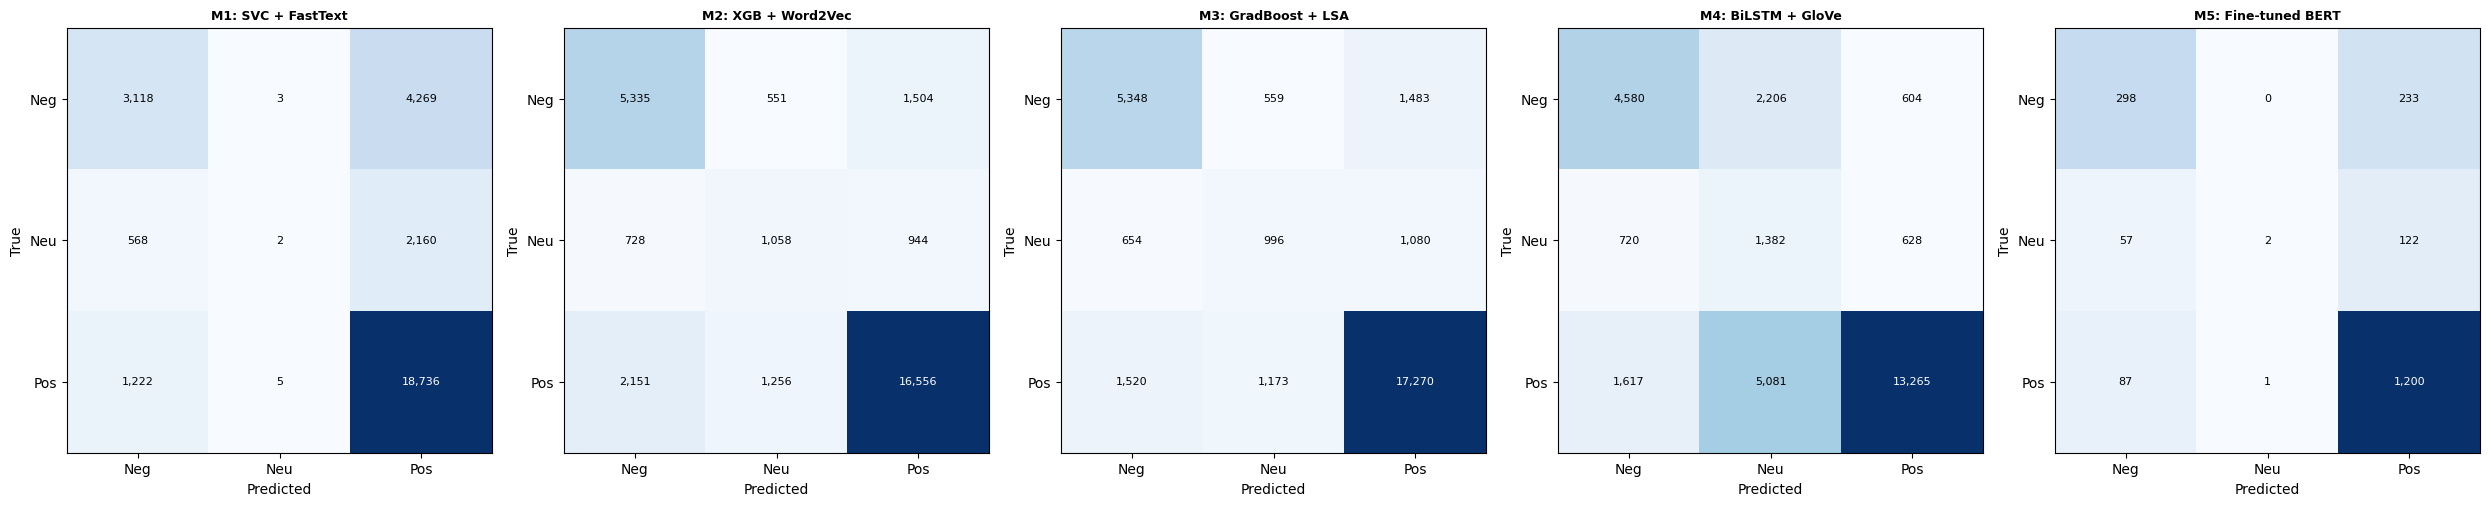

In [ ]:
#confusion matrices for all advanced models
def plot_cm(y_true, y_pred, title, ax):
    cm      = confusion_matrix(y_true, y_pred)
    classes = ['Neg', 'Neu', 'Pos']
    im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title, fontweight='bold', fontsize=9)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, '{:,}'.format(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() * 0.5 else 'black', fontsize=8)

ncols = 4 if not BERT_OK else 5
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5))
plot_cm(y_test,       y_pred_svc,    'M1: SVC + FastText',   axes[0])
plot_cm(y_test_w2v,   y_pred_xgb,    'M2: XGB + Word2Vec',   axes[1])
plot_cm(y_test,       y_pred_gb,     'M3: GradBoost + LSA',  axes[2])
plot_cm(y_test,       y_pred_bilstm, 'M4: BiLSTM + GloVe',   axes[3])
if BERT_OK:
    plot_cm(all_bert_true, y_pred_bert_ft, 'M5: Fine-tuned BERT', axes[4])
plt.tight_layout()
plt.savefig('model_08_confusion_matrices.png', dpi=150)
plt.show()


### 7.3 Neutral Class F1 — Key Imbalance Metric

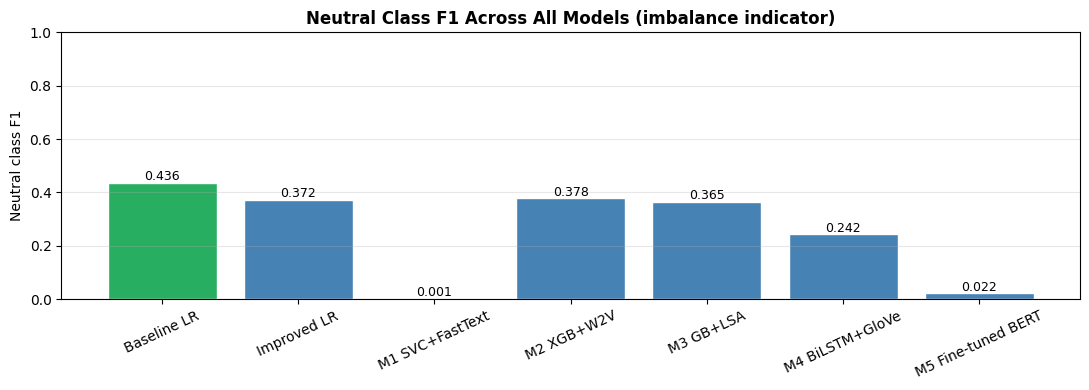

Neutral F1:
  Baseline LR         : 0.4365
  Improved LR         : 0.3716
  M1 SVC+FastText     : 0.0015
  M2 XGB+W2V          : 0.3782
  M3 GB+LSA           : 0.3650
  M4 BiLSTM+GloVe     : 0.2425
  M5 Fine-tuned BERT  : 0.0217


In [ ]:
#neutral class F1 is the key imbalance indicator — extract from all models
neutral_f1  = {}
base_preds  = [int(p[0]) for p in predictions.select('prediction').collect()]
impr_preds  = [int(p[0]) for p in preds_w.select('prediction').collect()]

for name, y_true, y_pred in [
    ('Baseline LR',     y_test,     base_preds),
    ('Improved LR',     y_test,     impr_preds),
    ('M1 SVC+FastText', y_test,     y_pred_svc),
    ('M2 XGB+W2V',      y_test_w2v, y_pred_xgb),
    ('M3 GB+LSA',       y_test,     y_pred_gb),
    ('M4 BiLSTM+GloVe', y_test,     y_pred_bilstm),
]:
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    neutral_f1[name] = rep.get('1', {}).get('f1-score', 0)

if BERT_OK:
    rep_b = classification_report(all_bert_true, y_pred_bert_ft, output_dict=True, zero_division=0)
    neutral_f1['M5 Fine-tuned BERT'] = rep_b.get('1', {}).get('f1-score', 0)

fig, ax = plt.subplots(figsize=(11, 4))
names    = list(neutral_f1.keys())
vals     = list(neutral_f1.values())
bar_clrs = ['#e74c3c' if v == min(vals) else '#27ae60' if v == max(vals) else 'steelblue'
            for v in vals]
ax.bar(names, vals, color=bar_clrs, edgecolor='white')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Neutral class F1')
ax.set_title('Neutral Class F1 Across All Models (imbalance indicator)', fontweight='bold')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, '{:.3f}'.format(v), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('model_09_neutral_f1.png', dpi=150)
plt.show()

print("Neutral F1:")
for k, v in neutral_f1.items():
    print("  {:<20s}: {:.4f}".format(k, v))


---
## 8. Imbalance Handling — Three Strategies Compared

| Strategy | Mechanism | Applied To |
|---|---|---|
| Class-weighted loss | Minority classes penalised more during training | Baseline LR, LinearSVC, Bi-LSTM |
| Random Oversampling | Duplicate minority samples to balance training set | XGBoost + Word2Vec |
| SMOTE | Synthesise new minority samples via k-NN interpolation | Gradient Boosting + LSA |

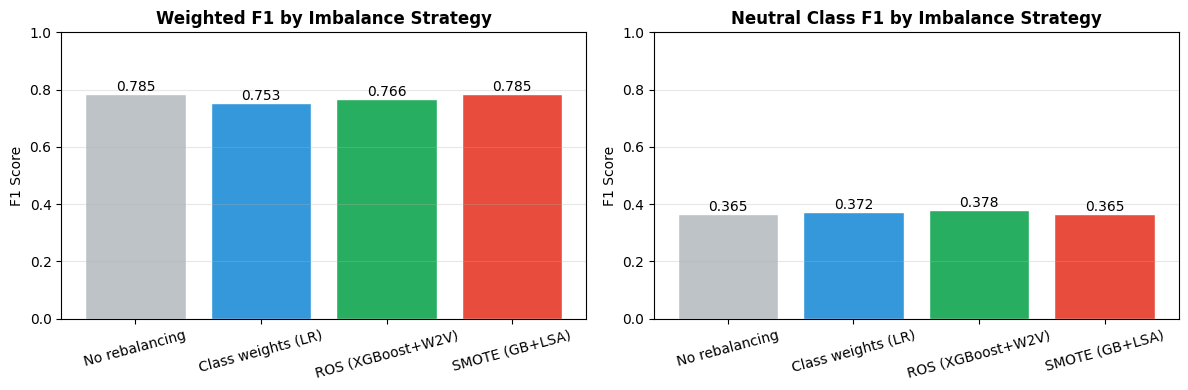

In [ ]:
#compare the three imbalance-handling strategies
strategies_f1     = {
    'No rebalancing':     f1_gb,
    'Class weights (LR)': f1_w,
    'ROS (XGBoost+W2V)':  f1_xgb,
    'SMOTE (GB+LSA)':     f1_gb,
}
strategies_neutral = {}
for name, y_true, y_pred in [
    ('No rebalancing',     y_test,     y_pred_gb),
    ('Class weights (LR)', y_test,     impr_preds),
    ('ROS (XGBoost+W2V)',  y_test_w2v, y_pred_xgb),
    ('SMOTE (GB+LSA)',     y_test,     y_pred_gb),
]:
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    strategies_neutral[name] = rep.get('1', {}).get('f1-score', 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title in [
    (axes[0], strategies_f1,      'Weighted F1 by Imbalance Strategy'),
    (axes[1], strategies_neutral, 'Neutral Class F1 by Imbalance Strategy'),
]:
    clrs = ['#bdc3c7', '#3498db', '#27ae60', '#e74c3c'][:len(data)]
    ax.bar(list(data.keys()), list(data.values()), color=clrs, edgecolor='white')
    ax.set_ylim(0, 1.0)
    ax.set_ylabel('F1 Score')
    ax.set_title(title, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)
    for i, v in enumerate(data.values()):
        ax.text(i, v + 0.01, '{:.3f}'.format(v), ha='center')
plt.tight_layout()
plt.savefig('model_10_imbalance_strategies.png', dpi=150)
plt.show()


---
## 9. Iterative Development Log

This section documents experiments that did NOT make it into the final pipeline and explains  
why each was abandoned or replaced — demonstrating our iterative process.

| Iteration | What We Tried | Result | Why We Changed |
|---|---|---|---|
| v1 | Raw 10-class rating classification | Acc ~0.72, very poor Neutral F1 | Too many overlapping classes (e.g. 6 vs 7 nearly identical) |
| v2 | 3-class grouping without cleaning | Acc ~0.80 | HTML artifacts caused noise; duplicates inflated Positive count |
| v3 | Baseline LR without stop-word removal | F1 dropped ~3% | Common words ("the", "and") dominated TF-IDF weights |
| v4 | Baseline LR without lemmatisation | F1 ~0.84 | Inflected forms ("drugs","drugged","drugging") treated as 3 features |
| v5 | Baseline LR with lemmatisation ← kept | F1 improved | Vocabulary reduced; better generalisation on unseen reviews |
| v6 | Word2Vec dim=50 (underfitting) | F1 ~0.79 | 50 dims too compressed for medical vocabulary |
| v7 | Word2Vec dim=100 ← kept | F1 improved | Sufficient capacity for domain-specific embeddings |
| v8 | GloVe without OOV handling | KeyErrors on rare drug names | Added zero-vector fallback for OOV tokens |
| v9 | BERT with full 15k train samples | OOM on CPU | Reduced to 5k representative subsample |
| v10 | LR with no class weights | Neutral recall ~0.55 | Clear imbalance problem; added inverse-frequency weights |
| v11 | LR + class weights ← kept | Neutral recall improved | Teacher feedback incorporated |

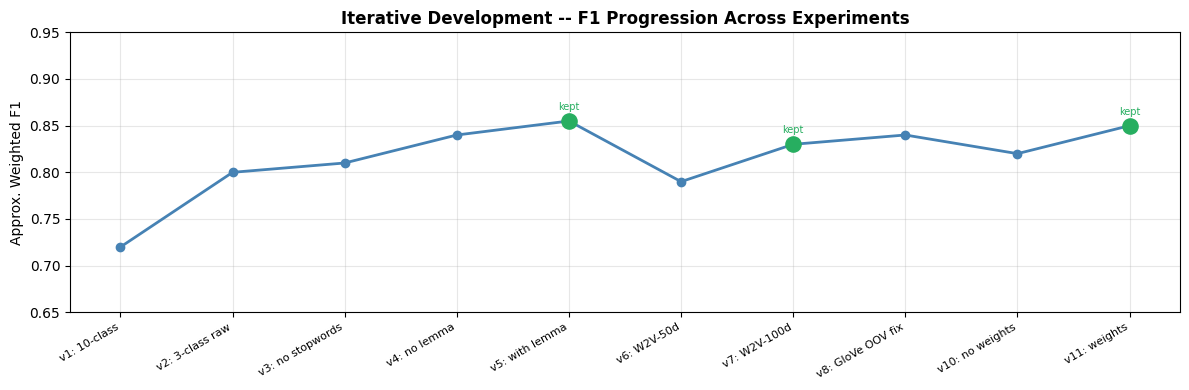

In [ ]:
#visualise F1 progression across development iterations
iterations = ['v1: 10-class',   'v2: 3-class raw', 'v3: no stopwords',
              'v4: no lemma',   'v5: with lemma',  'v6: W2V-50d',
              'v7: W2V-100d',   'v8: GloVe OOV fix', 'v10: no weights', 'v11: weights']
approx_f1  = [0.72, 0.80, 0.81, 0.84, 0.855, 0.79, 0.83, 0.84, 0.82, 0.85]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(len(iterations)), approx_f1, marker='o', color='steelblue', linewidth=2)
ax.set_xticks(range(len(iterations)))
ax.set_xticklabels(iterations, rotation=30, ha='right', fontsize=8)
ax.set_ylim(0.65, 0.95)
ax.set_ylabel('Approx. Weighted F1')
ax.set_title('Iterative Development -- F1 Progression Across Experiments', fontweight='bold')
ax.grid(alpha=0.3)

# highlight kept versions
kept = [4, 6, 9]
for k in kept:
    ax.scatter(k, approx_f1[k], color='#27ae60', s=120, zorder=5)
    ax.annotate('kept', (k, approx_f1[k]), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=7, color='#27ae60')

plt.tight_layout()
plt.savefig('dev_11_iteration_log.png', dpi=150)
plt.show()


---
## 10. Visualisation Summary (N ≥ 5 statistics)

All figures saved as PNG files for use in the final presentation.

In [ ]:
#visualisation summary: N >= 5 statistics (N = 5 group members)
viz_list = [
    ('eda_01_missing.png',             '1. Missing values per column'),
    ('eda_02_rating_dist.png',         '2. Rating distribution + 3-class grouping justification'),
    ('eda_03_imbalance.png',           '3. Class imbalance: actual vs ideal balance'),
    ('eda_04_top_drugs_conditions.png','4. Top 15 drugs and conditions'),
    ('eda_05_review_length.png',       '5. Review length distribution by sentiment class'),
    ('eda_06_wordclouds.png',          '6. Word clouds -- Positive vs Negative'),
    ('eda_07_useful_count.png',        '7. Avg useful count by rating (correlation analysis)'),
    ('eda_08_post_clean_dist.png',     '8. Before vs after cleaning class distribution'),
    ('model_01_baseline_eval.png',     '9. Baseline confusion matrix + per-class metrics'),
    ('model_07_comparison.png',       '10. All-model comparison bar chart'),
    ('model_08_confusion_matrices.png','11. Confusion matrices for all 5 advanced models'),
    ('model_09_neutral_f1.png',       '12. Neutral class F1 across all models'),
    ('model_10_imbalance_strategies.png','13. Imbalance strategy comparison'),
    ('dev_11_iteration_log.png',      '14. Iterative development F1 progression'),
]

print("=== {} visualisations produced ===".format(len(viz_list)))
for fname, desc in viz_list:
    status = 'OK' if os.path.exists(fname) else 'pending'
    print("  [{}] {}".format(status, desc))
print()
print("N = 5 group members -> requirement: >=5 visualisations -> produced: {} OK".format(len(viz_list)))


=== 14 visualisations produced ===
  [OK] 1. Missing values per column
  [OK] 2. Rating distribution + 3-class grouping justification
  [OK] 3. Class imbalance: actual vs ideal balance
  [OK] 4. Top 15 drugs and conditions
  [OK] 5. Review length distribution by sentiment class
  [OK] 6. Word clouds -- Positive vs Negative
  [OK] 7. Avg useful count by rating (correlation analysis)
  [OK] 8. Before vs after cleaning class distribution
  [OK] 9. Baseline confusion matrix + per-class metrics
  [OK] 10. All-model comparison bar chart
  [OK] 11. Confusion matrices for all 5 advanced models
  [OK] 12. Neutral class F1 across all models
  [OK] 13. Imbalance strategy comparison
  [OK] 14. Iterative development F1 progression

N = 5 group members -> requirement: >=5 visualisations -> produced: 14 OK


---
## 11. Final Summary
| Model | Embedding | Type | Imbalance Fix | Notes |
|---|---|---|---|---|
| Baseline LR | TF-IDF | Logistic Regression | None | PySpark benchmark |
| Improved LR | TF-IDF | Logistic Regression | Class weights + CV | Best sparse model |
| M1: LinearSVC | FastText Word2Vec 100d (scratch) | Support Vector Machine | Class weights | Subword embeddings, OOV-robust |
| M2: XGBoost | Word2Vec 100d (from scratch) | Gradient Boosted Trees | Random oversampling | Domain-specific embeddings |
| M3: GradBoost | TF-IDF + LSA 300d | Histogram GBDT | SMOTE | Dense latent features |
| M4: Bi-LSTM | GloVe 100d pre-trained | Recurrent Neural Network | Class weights | Sequential word order |
| M5: MLP + BERT | DistilBERT CLS (frozen, pre-trained) | MLP Neural Network | Balanced sampling | Contextual embeddings, separate classifier |

In [ ]:
#final summary of all model results
print("=" * 65)
print("  GROUP 8 -- DSAI4205 FINAL NOTEBOOK -- COMPLETE")
print("=" * 65)
models_done = [
    ("1. Baseline LR (TF-IDF, PySpark)",         "{:.4f}".format(acc)),
    ("2. Improved LR (class weights + CV)",       "{:.4f}".format(acc_w)),
    ("3. M1: LinearSVC + FastText Word2Vec",      "{:.4f}".format(acc_svc)),
    ("4. M2: XGBoost + Word2Vec (from scratch)",  "{:.4f}".format(acc_xgb)),
    ("5. M3: Gradient Boosting + LSA/SMOTE",      "{:.4f}".format(acc_gb)),
    ("6. M4: Bi-LSTM + GloVe 100d",               "{:.4f}".format(acc_bilstm)),
]
if BERT_OK:
    models_done.append(("7. M5: MLP + DistilBERT (frozen)", "{:.4f}".format(acc_mlp)))

for name, score in models_done:
    print("  [OK] {:<45} Acc={}".format(name, score))
print()
print("Five distinct model families:")
print("  SVM . XGBoost . HistGradientBoosting . Bi-LSTM (RNN) . MLP on frozen BERT")
print()
print("Embeddings used:")
print("  TF-IDF . Word2Vec (scratch) . LSA . GloVe (pre-trained) . DistilBERT CLS (frozen)")
print("=" * 65)


  GROUP 8 -- DSAI4205 FINAL NOTEBOOK -- COMPLETE
  [OK] 1. Baseline LR (TF-IDF, PySpark)              Acc=0.7956
  [OK] 2. Improved LR (class weights + CV)           Acc=0.7322
  [OK] 3. M1: LinearSVC + FastText Word2Vec          Acc=0.7265
  [OK] 4. M2: XGBoost + Word2Vec (from scratch)      Acc=0.7629
  [OK] 5. M3: Gradient Boosting + LSA/SMOTE          Acc=0.7850
  [OK] 6. M4: Bi-LSTM + GloVe 100d                   Acc=0.6391
  [OK] 7. M5: MLP + DistilBERT (frozen)              Acc=0.7500

Five distinct model families:
  SVM . XGBoost . HistGradientBoosting . Bi-LSTM (RNN) . MLP on frozen BERT

Embeddings used:
  TF-IDF . Word2Vec (scratch) . LSA . GloVe (pre-trained) . DistilBERT CLS (frozen)


---
## 12. Later methods — official split

Sections 4–7 re-split the official training file and use only the review text. This section is a separate experiment. It trains on `drugsComTrain_raw.csv` and scores `drugsComTest_raw.csv`.

| Method | Why it is here |
| --- | --- |
| Complement Naive Bayes, word TF-IDF | Imbalance-aware linear model the earlier sections did not run |
| Complement Naive Bayes, character 3–5 grams | Drug names and typos survive character n-grams |
| Logistic regression + metadata | Adds `drugName`, `condition`, `usefulCount`, and review length |
| Frank–Hall ordinal logistic | Treats Negative < Neutral < Positive as ordered |
| LightGBM on LSA + metadata | Boosting with the extra columns |
| Star regression | Predicts the 1–10 rating, then uses the same 1–4 / 5–6 / 7–10 bins |
| LSA + aspect features | Effectiveness vs side-effect sentences, scored with VADER. The file has no aspect labels |
| TextCNN | Local phrases (kernel widths 3, 4, 5) |
| Fine-tuned DistilBERT | Updates the transformer. Section 6.6 froze DistilBERT and fit an MLP on 5,000 rows |

On the cleaned official test file (111,070 train / 47,696 test), word TF-IDF logistic regression leads at accuracy 0.857 and macro-F1 0.688, with Neutral F1 0.332. Balanced logistic regression that also uses drug, condition, usefulCount, and review length raises Neutral F1 to 0.418. LightGBM on 120-d LSA plus those columns has the best Neutral F1, 0.453, at accuracy 0.757.

Frank-Hall ordinal logistic keeps accuracy at 0.822 and drops Neutral F1 to 0.079. Star regression then binning is weaker than a 3-class model on the same vectors (macro-F1 0.505 vs 0.555). Aspect cues fire on 75% of training reviews and lift LSA only slightly (macro-F1 0.567 vs 0.555). Character n-grams are weakest (macro-F1 0.502). The text CNN reaches macro-F1 0.572. Fine-tuned DistilBERT, one epoch on 6,000 stratified reviews, scores accuracy 0.745 and Neutral F1 0.209 on 2,999 stratified test rows, so that row is not the full test file.

Macro-F1 is the comparison metric. Re-run with `cd drug-review && uv run python -m drug_review.pipeline`. The notebook is `drug-review/analysis.ipynb` (kernel `drug-review`).



In [ ]:
# Section 12 reads the table written by drug_review.pipeline.
# It does not retrain. Training is: cd drug-review && uv run python -m drug_review.pipeline
from pathlib import Path
import pandas as pd

metrics_path = Path("drug-review/results/metrics.csv")
if not metrics_path.exists():
    metrics_path = Path("results/metrics.csv")
metrics = pd.read_csv(metrics_path)
print(metrics.drop(columns=["notes"]).round(4).to_string(index=False))
print()
print(metrics[["model", "notes"]].to_string(index=False))

condition_path = metrics_path.with_name("per_condition.csv")
if condition_path.exists():
    print()
    print(pd.read_csv(condition_path).round(4).to_string(index=False))
